# D46 · 프로젝트 ② 요구사항 명세 · 인수 시험: 한빛치과 AI 콜센터

> **음성 AI 전문가 과정 Day 46 / 51** · 4시간 · Colab (CPU로 충분 · 키 없음)
>
> 🎬 [애니메이션 9개](https://imguru-mooc.github.io/AI_Voice/day46/animation.html) · 📝 [워크시트 25문항](https://imguru-mooc.github.io/AI_Voice/day46/worksheet.html)

어제는 강사와 함께 한 단계씩 만들었고, 시험이 무엇을 넣고 무엇을 기대하는지 **다 보였습니다.** 오늘은 다릅니다. 가상의 고객이 준 **요구서**를 읽고, 만들어서, **납품**합니다. 고객은 여러분의 코드를 읽지 않습니다. **숨겨 둔 인수 시험 20개**를 돌려 보고 받을지 말지를 정합니다.

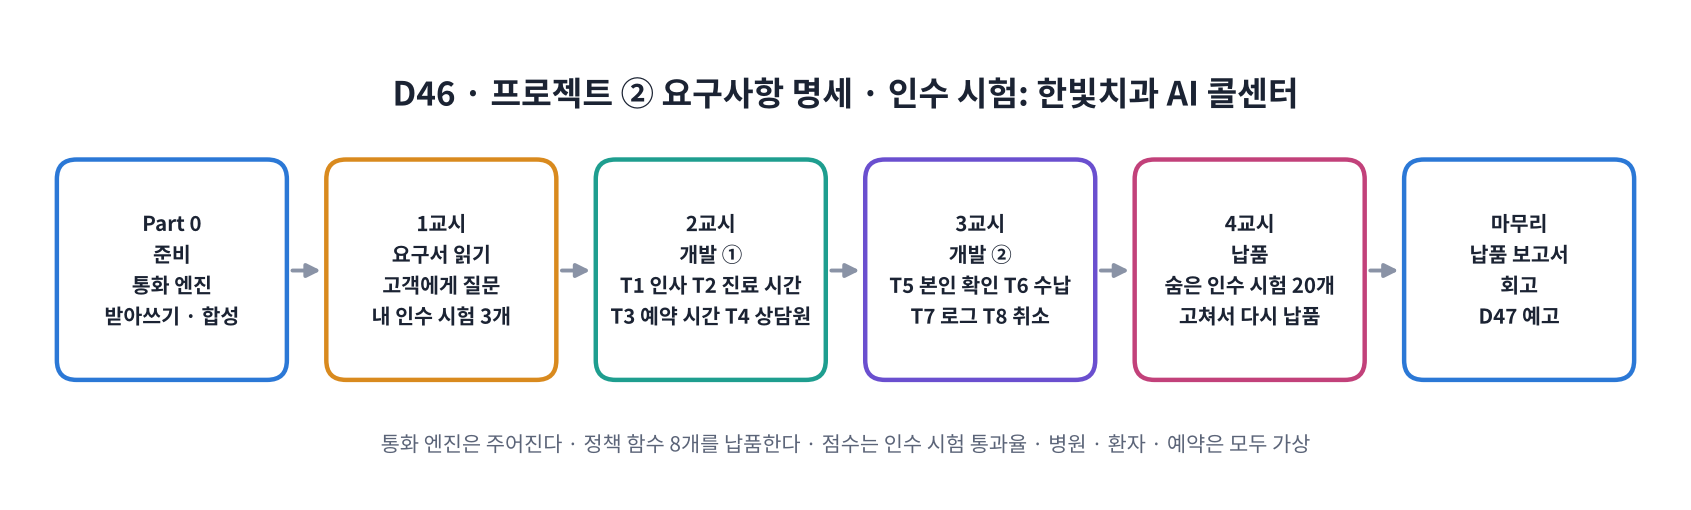

## 오늘의 형식

| | 어제 (D45 따라 만들기) | 오늘 (D46 요구사항 명세 · 인수 시험) |
|---|---|---|
| 무엇을 만들지 | 강사가 단계마다 알려 줌 | **요구서를 읽고 스스로 정함** |
| 시험 | 다 보임 | 예시 몇 개만 보임. **인수 시험 20개는 숨겨져 있음** |
| 모르는 것 | 힌트 · 정답 보기 | **고객에게 질문** (1교시 · 강사가 고객 역) |
| 점수 | 체크포인트 통과 수 | **인수 시험 통과율** |
| 막혔을 때 | 참고 구현으로 진행 | 기본 동작으로 진행 (그 요구사항은 **미통과로 납품됨**) |

## 하루의 흐름

| 교시 | 하는 일 | 내가 쓰는 것 |
|---|---|---|
| 1 | 요구서 읽기 · 고객에게 질문 · 요구사항을 시험으로 바꾸기 | ✍️ 내 인수 시험 3개 (`MY_TESTS`) |
| 2 | 개발 ① 인사 · 진료 시간 · 예약 가능 시간 · 상담원 연결 | ✍️ 정책 T1 ~ T4 |
| 3 | 개발 ② 본인 확인 · 수납 연결 · 로그 가리기 · 취소 규정 | ✍️ 정책 T5 ~ T8 |
| 4 | **납품**: 인수 시험 실행 → 고쳐서 다시 납품 → 납품 보고서 · 회고 | ✍️ 요구사항별 통과 집계 |

**오늘의 규칙**
- 통화의 뼈대(듣고 → 뜻을 가리고 → 되묻고 → 도구를 부르는 엔진)는 **주어집니다**(`hanbit_cc.py`). 여러분은 병원의 규칙을 담은 **정책 함수 8개**를 납품합니다.
- 쓰지 않은 정책의 자리는 **허술한 기본 동작**이 맡습니다. 노트북은 끝까지 돌아가지만, 그 요구사항의 인수 시험은 통과하지 못합니다.
- 인수 시험은 몇 번이든 다시 돌릴 수 있습니다. 납품 횟수는 보고서에 남습니다.
- 병원 · 환자 · 예약은 모두 **가상**입니다. 시험 속의 '오늘'은 늘 **2026년 11월 23일 월요일**입니다.

---
## Part 0. 준비

D44 · D45의 기기 안 받아쓰기와 합성을 그대로 씁니다(인수 시험 가운데 네 개는 **목소리로** 들어옵니다). 키도 GPU도 필요 없습니다.

> 🎬 **애니메이션 D46-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day46/animation.html#flow) · **D46-2:** [통화 엔진과 정책](https://imguru-mooc.github.io/AI_Voice/day46/animation.html#engine)

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1 ~ 2분)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "requests",
        "click", "filelock", "rich", "typer", "pydantic", "httpx"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt soundfile sherpa-onnx==1.13.8
print("✅ 설치 완료")

In [ ]:
import os, re, io, sys, json, time, zlib, base64, tarfile, warnings, importlib, urllib.request, datetime as dt
import numpy as np
import pandas as pd
import librosa
from IPython.display import Audio, display, Markdown, HTML
import sherpa_onnx
import importlib.metadata as md
warnings.filterwarnings("ignore")
SR, NUM_THREADS = 16000, 2
print("sherpa-onnx", md.version("sherpa-onnx"))

def verify(cond, what=""):                               # ⭐ 핵심 코드 셀: 결과가 예상과 같은지 스스로 확인
    print(f"✅ 확인: {what}" if cond else f"⚠️ 예상과 다릅니다: {what} → 위 셀을 고쳤다면 원래대로 되돌려 다시 실행하세요.")

def practice(run, want, tol=1e-4):                       # ✍️ 직접 작성 셀 채점: 아직 안 썼거나 오류가 나도 노트북은 계속 실행됨
    try:
        got = run()
    except Exception as e:
        print(f"❌ 실행 중 오류가 났습니다 ({type(e).__name__}: {str(e)[:90]}) · 아래 💡 힌트 보기를 눌러 보세요."); return False
    items = got if isinstance(got, (list, tuple)) else [got]
    if any(x is None or x is Ellipsis for x in items):
        print("✍️ 아직 작성 전입니다. '...' 줄을 지우고 코드를 쓴 뒤 다시 실행하세요. (작성하지 않아도 아래 셀은 그대로 실행됩니다)"); return False
    ok = list(items) == list(want if isinstance(want, (list, tuple)) else [want])
    print("✅ 정답입니다! 🎉" if ok else f"❌ 결과가 다릅니다. 내 결과 {str(got)[:110]} · 기대 {str(want)[:110]} · 아래 💡 힌트 보기를 눌러 보세요.")
    return ok

def play(y, sr=SR, label=""):
    y = np.asarray(y, np.float32).reshape(-1); print(f"🎧 {label}  ({len(y) / sr:.2f}초)"); display(Audio(y, rate=sr))

def silence(sec, sr=SR): return np.zeros(int(sec * sr), np.float32)

def cer(ref, hyp):                                       # 글자 오류율 (D10)
    r, h = [re.sub(r"[^0-9A-Za-z가-힣]", "", s) for s in (ref, hyp)]
    d = list(range(len(h) + 1))
    for i, a in enumerate(r, 1):
        prev, d[0] = d[0], i
        for j, b in enumerate(h, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (a != b))
    return d[-1] / max(1, len(r))

In [ ]:
# 📥 통화 엔진 · 인수 시험 꾸러미 준비 + 모델 내려받기 (한 번만 · 약 280 MB · 1분 안팎)
_LIB = (
    "eNrVXP9vFEeW/91/RaXRyd3ZYeRvkGSID6GF1a1Om0gJe1E0GVmDp43nPF9802MIskcyZEIc7L1AsMEE22sOEyDyXgw4wWjNnnR/yv7o7vkf7v"
    "NeVXVX98x4zO1lpbNC3NVV9erVq/e9XtuyrNbKmv/qfvBq9eDFvjjzWxG8Xgua+63mTrC+Kvz9BX9p3m4tN/3NhWCjGdxfal3ddjIi2FwJnn0p"
    "WitPgoVV8e7Bzpr/aF/4V/cxQgS3d/wby6J1/afWvWUR3F0OHjfFr0SwuNa6u4pfW607Xx/s7aT7hEDvtv/Hbf/nZrC+K/xrT1vfLrRWVmn6wf"
    "MvgvV50S+X6kf/wYvNlKBxraWlYH2fevEKqAeP50WwciO48ZO/uOAvbqWFHay/Du4A4otdA9bBz0utladyjGNZVl+xPF2t1UXNTYlCvu7Wi2VX"
    "5D1RqPf1nf/w7JlPxSie09RlDw0MnUyJwcGUGBp2xCE/x9RGaUH/xqqQG9sM1pvYy+oWXvX7D9aEv9sElveXg++WsRen75OzWMzCC9AMNPV/eH"
    "qwt9C6jnn7Vt/5j86dOY/+WSu4sRXsz+Ol//iqlRHxdgrtn5+CINzDTwL//IdL3HVt29+4hd1zr24If2eNZtCAjWZrecnfmG/d2OMxRlsEX1z1"
    "F3dp2MHzeRwoD9hcwTkK9aLR98Hvf8dIgqfQDVJZ/q2beBoi4E2COUzvmlt4GqGnxa2g+SMaJ2jA3W3ZOEmN9f2DF8/QeEf2+H/4IxrvUmOl2b"
    "r3NRrvcc8uLTQgH9Wyg7Illx4cavT97rcfSNot/ikcvb4rW0PcurYvW8OytS1bI9xa3ZKtEwONvg8/OnvuI8DKWvWam6+X3UqdKEIMQr+Jf+h3"
    "JS9/T09WK66V6zvz8T8zAtEkIt6dXf/OlgDlcD4kPcHqQrDyurUCdrm95n+/e/BqCcxxOlyA5ty/CekAfxFTE1M9lnL3+GawPE8zg4f7IDSmpU"
    "N8MM3/4StiyoMdiMl/LAZr2O1WCL1P8a3EmhZReGCdLcGSCS5qPiNZBw93W0vulabf3fHXX/s79+U6UBU4sGX/+UJrda8rso2+T/7pU6bReKnq"
    "uQUCdPByj+VmXrTWdkGmYONLLd74n/9o7wgUmKzO1DwFTJKgSQAl0cMXmLXS9BfvJcDr7m6bDilXmqmMT3ZYZfNmsLit2m3I94IurJlKsR4dCE"
    "EcHsB5AMCTYK3JSgRUjpQeiePOVWzHv7Yqh+IIeNjh6NfzU24lgf7dm8RiBOvHPaERwPyNBWPBo+2k0QftxRKQtYKHzeD6g1AJMwhMF2SFni90"
    "pUSwARZcWaJTuv2QtL3/w59bd0xUJIopKPz5g+f4Hbx8ElxfSsVPWkACgu92/T/sCH97N7j7FeP8TTO4Nx8XuVxfX8GdEBX38ljhgg179wY/x3"
    "iVL66y2DBWoNoj/+d5qHs2DP5jQhkKdUGezZJ/+3uHD6Pm1mdqFQhBfnq6TmybnbWKLAtnBkO9Quf0at7/cT/Ymo8J3sDgwODQ8MiJk++8y8If"
    "UzYJM6EVClm144ODx4dOmPpicCAzMGA1Qg5J/IRIDZlIkUptrkH6k0i99+47J0+MDA+1I5W0UG1YDcewOnk0rIZNrPydFfALVE8SqxP4OYmfdq"
    "xiRq0TViMxrEYYqxyt6X5OEEYakntYrOzCBelbpATN6MlK4J6XWrGJ/34pGfcqxLGjLEJGwWwm7+QrV+x8VuKcE6OjvDbeFgTeMs78lj2diWpN"
    "5EWxIgoXsorlco7EfaJYKYzRK8a/lPfqI72l4FhM1wv/W5iPJhh946b//TbxuhaHnb8Qhe3g7nVSUE93xQc4l5gIECltO98RRVGcoM0o45o9Pp"
    "LhLUkkUwoW72KqOkYbtScny+UjC/ExnOmJzPCAJf56/Vu2/637TTFMWop1qsV4TqZEGRqtnJ+2i5V6StASaW+6VKzbVsZynFMiP80OHdyHzaZF"
    "OE+K9+GOCLfkuRqsdUpM4tUo+uSA0XDEpDiOZ5MmE9ZsfrohZjGjAWwsuNT2hCVmyw3CigCUFXAr2j/7rkWvenQddiymFSQRBgfhmIqhE1AgAs"
    "6p9FklIQqRj5yeqFXLWAuHVs7XedVTBvKFdLlaqU82CBQahfyVBsGb/eRstpC+7LpTeGM7uYaG3ndM/HV5Hv+xWbh7E9qFTBxceuG/vsUcRPZv"
    "pRnc3hUHe/PscK834VchAEE3uztgMeh4ClLIdIHbfpwnTjx48ZO/84zV/yt4mpvEk8H6kqNWjGSA6VcHN0J+q0BwlOMCJ8N7r2Pv1JeuudOl/L"
    "hrW4JUgyVZmXj3ckpMEfvatiV9f/QPgElty7+2S7tESCGbPzxBiIXmkKOA0w/O9DJNr2c0HW3GAkcPmhNvF9xSPW/jlTc65TjpiPoSB+LRmpv2"
    "3HxtfNKuWTZpkecLc2R2sV1YWTvbMebIOeoYsG8JivgricbxDmhwT3SeTkdcPzmbBnXdz+1y+mKtOjNtD/FA+x1eRr0bdEiuLYmrJXl7wDnKLj"
    "8rzA6mhhoOthY9d92MDvEk5lcAJQWi1+0IDyf+YuhISPwthO1EM7uNaEAMR5AgOOkNR/yDeAdABuN4agEHRclHIYZcZnsjUTKVDWlRwxSwGiVW"
    "78X5p0R1hjp5vpaCMvEwaEOginW3xozIinFO6sE5kuJXT+aCzXn/y6vOaX1oczKqm5Ph3JyMF+dkpDgnY8Q5GR3OybhwjkbTUDiPczA+NNOBso"
    "SmWJ0LoWbJV0HMh0BvdSt3GvGdAxXqnOYziaRvEvtIHLvJnkNE20LxYpEoy8yJ+Dcb9eZCQOUiIA0PmJOHFW/vrCrGts2VRuIrjThswaNmcmFE"
    "uOmLrjmf1Ixj6hGDaVghaQtE3jVT3ZKLSCvlCBxbbIrHR6qHjIqTsCiT4ldssLr5Mf4Xj0Q/Wc5+jldf3EL8qqMFGZkMnkAzRFOyDkzFZGZgqN"
    "DIzJaL/GCZnIlBJmNq183kzpgTcYlZcColLtG+OZOSBhOWPZtpzOqZ58ZcBwZOTqRS/vnL+WK9WLk4+ps8CH4k/f/x739DKsGyT2dI6xK3boaR"
    "z1yyHQ5RPXNhxEhdZP6+W54jB4p+cS4Mv/YQyqgX/Ou7ZcfqrIwkDt9TXDqng/l5lrcby46dhTo43tp4mJsdSo00TjvkWwB9EgdmBBuwoEGUXj"
    "t8MMn5TKnUZbiTTb91Ovc2SxrTXxNWSVDSETRZkBwcUw7wrlKtS26mpBJnaxYsmSSiPFf4BMJQw3+8gTbnsOAu/Lt8erl38HzJcqL1JQOMsYB5"
    "tueEutmy0v9aLVZsr16zLXgQnIOMFEmw9iB4tdlaWj74adtSmnpcbnKckOw1RWIwzuzKE7yIr4JVDtsAAb6lwaHsBCcVMx38zAXQXuk7iNiceo"
    "Sa04+wTuEjmyOLDqUTN3e2bwODnxWOnwaEYRwrP4w0LIMJwoFZ2vfq1RxWUY9EBWPnueOnjY4u5MmpdY4yUiFi8lFEk7Nqq/qANTc5SucmGYHp"
    "zMHF/14VdBBH/+r6nP/tS/zbcqjZ3HJOy0iJWjeW5yA20hCOwGAdadNOSH47vtj7b31WcN4MlH2a5kiAvaU0ScvBw2hJXkoHj/qwsDKeroPTvv"
    "1ntihRXMAODLKbX/qPVhGVt775mpiaImgLfpd8CN+ABJRSVE1CzwYoyniqiwS4xkc4VezQBEV2hIhv+a+eAE/E8FbcdzcGh/PJKZT+YDQfXjnQ"
    "SU6mbYTT6PiMadGoOHBFBQ05JpUJ7zRnuKXGohLCLxjP6CVS4uhPoIS8I7CcbI+AKIorD/Fu4XolPIjeBy8TjEnyj+cr424pPAHKxsgNS+opW8"
    "U5SjZIO8sHf9nTT/+1LE3YfyJ41U/Pn3Dvj3v+w/BpqwmdbKw5ma9cdHusKUVIShDD+eEraiDf+Xg+aiNLiZs/XvvOXrBp9m/vwdHmHoYEYTEb"
    "fDFEF3fXVpWtJWniBK6lbnDCnuBr3XCky6kS3Ja25gY9Zf4+IroaqBk66QIaVLlQrU5Z7Wf+6bmP4ed9iONN+gxwDpQ/4G/IveGqRHoLwfoti7"
    "k67ld8xSfSWpz3N7fCpz1KvozDXnji1/lS6Y1Sx6Tr1K0p4hhx8Gw3Lc4OvUeZZM/1vGK1kq7NVOii9mDnHqc7fngS3LmFTc9U7OD6TX9xlW9t"
    "H990OG9DoV2ruSuzh/t04XRtjZ7821syd0N+Dri/WB8bsz23NJES09VScfwKUpYXRolgnbIe9EOD09Mp+ZtShPwgRXHUAEKHpLPoClYchseXPl"
    "IAkTuVa1peqcr579kGNer5i27UN5EvlqiPLucoIxj1XJ6s8pxGfIlS9aLCz72EVTzdgINGyassUrf0L4xYmSrk+ntMk4inshWWqApLlMQ+q1DN"
    "cfgls86OWgCdhFGiK5zIuOeIQLMNxxzDprOSi3BBxKNOx73kHSGRd0xekuPg6QqCj5uMJrSK/2AdSbMHa2AMfcPDt+s0sJz3psZAK7pOO3i2E7"
    "xao6QarieQjX6CG4comiQiuEQEoJOJZeMNKqexP5DYdp3YCGzNzQ5wwtYChT15tPqc9CQLrytQAxRaSFbLWho/K2e72cGcIrI6KMeJL+OWzIXq"
    "1Wqp0yr0vusiCENpHSRc3exQjjzKoy8IjVyoTkx0WHNC92WEAg8PRK2A5EmMM6k/XETxIEgeMgYEo1ZP8KjEkTgma4cEToX7u1hzXfLjsD/HyT"
    "kRjymsFJ8BMBgSKW7voowJDNHXwmCCxzjWj3rfEQTLVEsLMCb+469JQXUlu/QME6Q2hIHEX2MZR0wLllQQOc5NmJ6HXqziugVvbHKmnK9gvcQs"
    "DTVOT00dS86ibXE5BPIZkCPEj0g07xw83wkv77cPnm+at5Mbm2RdIUskhLg13dyK33DyooeSmO9Qs2UKP5MYl3DNxN2cDhzMmeQi9TRWnVIU80"
    "q91Mex9rsnql+h+0qZP8dtTaQzxifd8SleQ+VzWvdWkJVg4xOs4D735ipNgBvhL/5JXRDDMaCEu7r4pQz++lK48/FqwQXn66OK4NNJlfS9Fm1E"
    "32aFNiiW7ZJwIIlwAjIxDyDkllJ6ujpt65qNKKRJQggLEvQMVe0Rn9HpyFDSwHqdQHErq/yZXIyjL7m14sQVzdMhAx52ROxA8hGxF0r3bixhL/"
    "aI+vIQMqpogyqvul/LhRuAqdKE14brlKiAuUYoJdctG3a+NuNC8rvHyDzApGslQ0tlpa2DthQVs7c0oroZGPeXRswBcp72FAlpipjkaONtJml0"
    "QnPNzoTU0rRJdkBpnl0hSKWRpOizvomLp6lsQngS3KmOjGDFDoYvpNaaXOUQldpsxkttyMk77Da1W82LkXUmB0OfHV/lhs6aSeH44YAQWvYkW4"
    "6Nw4l1axA/ApEyzy4BJ07yHuozQZBd0hQ6+AY1DM35Jnq2TZHGfa1Uh1OTu5KbLULMT7UpC5JR8q872hzNWWyyI0cxOgR4m/VQrlKHxJT0c7FK"
    "Y2enMiKetEa0bdabtUU9bHuVWjJuLU2vXI5Rys640pHv5V16KpZTVPmwS43YZrPaV5cixFEWy5AnXVgYcktebUhBpa7DtUeGtm3og8NH98Ucrv"
    "jYHqCcnhvJCMOhn5lmKgKi0xZPhB7kjOfW3sSVoTvOrIFkztBpOGhiAE6ZZXNO/Pqmi/PSw2/RkcPfy4PpiHLRG7tQLJWk13lELPUEwhMZqmtP"
    "4S/s+ouvoP1+EXQRo2p+0cmguGJEP1sK/H5rNMY9zPyRSnmLXIZqZaJYK1uJ4EizlJw6ClgpwdNUqM2cN1oojteZ6/S6kZwxa1BMDMU7Sr9Je/"
    "FkCh2kd0ICmHRO3EvYHMQzX8fNhdRj1hjXj5gbIUNaIT3gOLZyQ1Iixv7KQtiAR7t2LyHeSQZzRs9gjnhaeqYsWtozHxUDHWAdH8wl4yd1KxNN"
    "7etoX4iB3EtGNEPbiDtUcieH23YZCJGH1nFum1WJFAjTu7Pt11LAcMfyFe8yW9MoEx7X0qZjSIfeAxNiGsO8JJISCYVn+j6dWbRL+vCDD+X5RW"
    "ZT7reTD93FA0L1ZkJCzVJmI7OvwoIevs0hyCLDl/BF2BmqXfSUbUXsMJWT9pXGc01345QOI8IyM63jVV3hhHVmVg/pp5vlfs4JvP02QW44xnwu"
    "A5Th56k2oVeSHkq904ZpRD5OW6SU8Kd4C2ytI7JOqIwoeU93zXLYWV36RZOy/fTYn3Ma/J4Nv3xPj/SeMoT+T/fizlQ7uUlgwYBH9JCT/NLXDq"
    "nNc+gNmuwluzp8Q1qSCWRmQPkifvQX8gUtHlEoXGpLSWFYuDKejcINj7hGFhJMJXhGVg+omANAOwSRNJ8lhzZHdKAXnSVERveelzPIHo8vtMge"
    "quo7gUYmS7MDeL8DM9BbzQopMctN7V6CzdUr8lLQEpTOkdG+Dl82dd20qb3ktUQP/RXqri6qipxfI7vrdD9dFUXXkyFAjxNWZIadZSLPNk71JG"
    "G2nzREf64jJaNOTdCwYrfJRYbx6IZvWWQlP93/JL78MFihQv6JRvSX0+tmIHQEsvRQ6zKVhOr6v4eCl/SRkR6qb7Xepf+NVi5HqSM6F34h80fO"
    "/42OrrkeklWFmRKRRZkMFCnjdy4qITfR0AXkESaNNuUe8hwGdWA2equ5jHmI00JJW5Ckai8FW7msyUHGkmIV01ra8Y+dohIqDGy0eYp0fLq3O4"
    "w30vpK31YuZ7qqUUVjJyYnykYcZbpijGh6JytSuRzDrpt+6abCeyiZIx44KY35jsqX76H/PyjfmNx2cjjCXHC+orZFySgjFRx6z2apawcN0Ssl"
    "hehyfT/U1qsqt8ruaRgqU6Yq+l7odaj13igr9TfwRb6jL2cYm9l83Hab1of3026texqIXuqxm20IV6Y79SWuu0dpblcn88jqPqHq2xz3mluuXg"
    "JZ3li1t6t1xXBJlZ5U1ZbxVY7kmkOUcDddF33vkPxS2vwqAanIsbrrUbWKV4/u671pNz8lt5Tp/k2ykCUanD3+ZomSIjbqDZBrxsd08luilC5A"
    "kLfFjvxCjoYGW0tpuUyGLob5jseWKWpcMqNOZIGFBntX6Wn9bYZDw3n3lEvG2VFdhC0RxxERMUgVZak3Le80FbWIB2Zkfa6HlJmXv2LlIlbgiT"
    "pK48mcpiUM7Rk2TDRNBheXqsVxV1U48wiZWJhxYmVshNcY3znZ4ykJP8VIO1FRpkTF/XzaHQf3ObJflYx2nCoRnkK8j02OI8Nxiq5LacelfPlC"
    "Ic+36EghquJSuvSN3bB3vDKn74uQl6e8TlZ+yFXnsgRJzHB6XZURkJEmBNj4gowefyIHQ8bPpk3IFwlNQtDmBWT5KuFEy0M+VRaKR/BqWerN8b"
    "jjdBPJLx0qEedp7wvjpfo8KSkKRPfPOYqi5Ql7bo3jVtwJcaf1GV0JRbsX3ebF9m0UARjfycXrA2QaSu2UUeev5oAa3c4zG01xZjuem6fFdD25"
    "E1FeEq8NiQpUdgwPvY1euPQCHFUcdNqg7n1zuEC4DXQbziH4XtCQF8c14fiU1w6MTw45X8nN/EDUJbHGLPNwB3OdAU/mDbB0br3BOp3g1vJF8N"
    "e/5Esz7rlarVpDzQZVMz7ivyShLrh1oeksYdDQ39tdypeKBaWd3+B7Q/33IlZVPRd7GY832j/uxCd1xQo0JGwS+VqUKZYqzXwvFV7N/TcuRKrX"
    "uo0gbYoRpaKngBDJjGEzanakhJUGjtvMzsCVfozBZz1gqE7xj8iQdVoZChQKY7rkqtlyOqnOLgosJUKDrQUsJYxiFJOLUyYXpiLOMVW8gSRO9u"
    "PzZz46z3/2YfZNi/nIAD6+Sn8QJawsnjfKJ8y73AfEXf1kdV/gsvebe8HGrX76Myb7qMnEX0gRLbgTC/he5Ikkf1TJk1F2hD5dXlnwv1wJKy/T"
    "wvzjLuZfIDj043f5gXU8Ya0XwefEVzK67NP8Uwf8NZd4L6whFeq72ZNhlWm0vl7BqO4w4OtPpal8MMMFHGq4efUVjud7AelgZwQX5KvR8evrcL"
    "y876VUlvqsOSPvyfF9E2ki9g8lAOPaKpzdvkx43RcbI1fAJ3vQAtxWG45CmBhCY2rXVaYu3XOqT8jL+IR8THpK9gT+yMRRqv+4hGeXP37Fd7Hy"
    "L/RQi8vcNUOiNgfpF9O7e8ilPTH+0389Ymke5QlUSUIun3QPObuDP26Drxjk6aIi9WYYfl6u4bNoooDhWZRJ9eKKjXbBOoL7w26uxbbfzlNGfS"
    "rh79droEqNs6fYgh4j86sAGn1jECvI+3zcxbme41+onJUQ2oYpzapkPEtI5WJL1MJP36iAnhrnwBTTHh544VrSmZmI/SkHApgxCCIrSPFEikat"
    "2uj7H10e4Dc="
)
_SEALED = (                                               # 🔒 고객의 봉투: 숨은 인수 시험 20개 (납품 셀이 엽니다. 미리 열어 보지 않기!)
    "eNqtWG1PG1cW/u5fcTWfxsRGHmOchA2NumpXrVZqpWq/EWQN9lAs7Bl2PDRFFRKkk9TFSKEpLqbYkavSOGSR4oBDjJbdlfbn+F7/hz3n3nn1Wx"
    "xpjZBm7j333vOcl+ecO5IksXa3d9kk/WqHVt7KrFllbx6TO712Pdq7vCGs/JI1dghrdFm5Rlil3j+qkWQCpmdhyTH7vsF+PSP0cbe/16VXu+zo"
    "gO4dElatsqsqbMnsOqE/n7JfOr32T7RSppXTWUmSIvnihmFaxNRiJKdampUvakQtkZwVWTWNIllT9ZW8lclmiSNoqeuaHonktFXytamBvP61HF"
    "2IEPiZmrVp6kRi1TJ9DGfWmN1lvx6ienV6fcKua4jj488J+36XVjrs5ABmavRRjT1/7GgE8Dqk/+Rt//iQa88FSf9ZmbXKpP/LHzDAGjZhdRsg"
    "Adhr1tinB2fuanreYUc/oAR9arPjHfpznb7o9K73QY37ktB6zdg0SxlVLz3UTDmnbjnKW+pKQSOL5Dup//RH1riRFojzxK1eO2VNm9wFs9Ornb"
    "7dxpH+iU3SMIL7t0CmZdPf9wERODFGWPOAVc5xtm07O6C8MrRD0tvBN4MU4zp5P6n/pMkVetIEJO/TSRmhEz1rD6t09ITtvR13pGMDPMw7sl/v"
    "wI5BPYnUu3yLw0Laexkpvc2PyK9CpG2RfIl8YejagnesEz7cEUuuF5bJLSLB3y1vHCwhBj3NMKomHxwZ2h80WBbxkF3TsuuZUsGwZEyAGMEUgG"
    "RYcQLjYQ6iImfN4uQs5kS+ZKwaZlEV8tHZh5q2DtvJ0T+RtRgpgnRR3ZDzuiW2mi1tFPKWLC1IUZCwYHqNzJB0AjAUXXvgGYskveClULZglLSc"
    "0LuglnCVknSXzSX8NfNEK5Q0otz2J91NLXKP3BXDhglvH/Gd/DN4IkgBFe7BbqqeI8qcWHVvke+hpPirv7CwqWfXvIVFohsWyetETsTg9Kgvt6"
    "nnLU+M84acWxE0I0wTkOXTIT9JxrqTsbqm5UqZtc2iqsurar5QgtXat5abuGAbfJ01tY2CmtVkCBcISyka3IwvIx8tkjm0hapvyQ9RZYuAJwl/"
    "lCWPlXA5e3ROn+/zp9YujkWjQplvNDO/upXJqoUC8Ie6sQFu1lWMGLRuKkyFOI2BjhbCYOfmxcElCddAIIML8SkwsbEGgtLyUjy1wKf5tuLsfC"
    "mzki8UkHI/1ABjIJeBfs94Fl+0WbPO8dZ2YZi9aOBL/7hGr8r4RC87UHCEQZBT6LXt2aSoltYzBUNoJcxRWpSjrn4wCCqakAmbK7IpyQnlQS4a"
    "v/8g991cLLUdvy/DU2o7Cnub0gMlPgO/+IOk5HiZ74E666gz39vnDGfvEHwdNFhKcI6YkSB05QIEnh4lcaJEQzbBVQ4HqDp4VM9qBe7RjBOihl"
    "8eAg7ls5BNfDoS+erTv/Cy4VZDoEH3MeYkmVNtYCb4CrM+98Cc/wIzgZiHqcCbR9NSKBJBKPQOW/jRApP+C8y4/oJx9xGV8YyAyngv25HIn7/8"
    "8q+AcUlie6fsZgdYlrZ2odqUWfVfot5BP3IFrQXwMY+VR8jEboFSElBynJne9Q59fcNO/VqHowklEU/CLz4HP2k58tnnn3zy6Rd4YgQMm89hZf"
    "ksoaCoqf0d377iL1beKmi8SF38gzdGj86h7SH08ifsLaCVoC9slCupWyC1tAyP2rcbWhatvSTjcAmmgbagrARaFGk5urwdCx6dnPpo3pFANWpC"
    "9Z3yaLFm+NC54KHJ0KGiODrVnYiKznvEQIUPnD5SHlrDfdo8Jez3G9GnSWOUVFDJQLMhSMLrfvgrP3cYQmoCBLeVGdBKBlsw+w2ygfSNkc+i8N"
    "/MTS2IJtgF0Vc/EL/fcfpJ7Pbeg8ZtlEDpGDAhMHRmhERaSAzAmh8Pa0S7NA0kfxm07U/tQN82BRpxzLCa6aCac2E1ee6yRo30um162SX9xkEo"
    "WXjK38LotE+HDrcMo4CiKwbU6BicaJmaahU13eJ7B0gCpZAucTyZSKbjihJPpoQqRT6qJBYSCRzgBXEhQBE4KIrhAqcIZAhOENuDQG+PB9o/rk"
    "J28lYX6ACvFC5r8fa4uoepF0I9gFU3MiG4PFoc68edUBE7NsU9Y9gPdyb4IdiSOzc2vh2BsttrBykkwKpu7CLjjKTkzrRZ7eatSIEBpAMw7k6A"
    "EQzfSRjQCRdl1M5v38N1AiD1LnYwbT4UzJg0UBKT9O7Q1xAd7XPiX4t6b6AVKo+3fPL/YnnnZL5sWGdlvM60BZfhHdr6kbhJDCTYAkMfQPdNr8"
    "BuzakoJwyKHZ0z+zWZEtrsZGxBQscLPavatHLs1PshrMnxWAUgWnkJF376W5229l2LjQTiRRF8F4GFHMnVGRR1Av9cpQ/0UvD8YcVDBToVdtJl"
    "F2nHYR/67BSakp3eRUhv1322Mzeqk/L7pUYHJ+mzd+w5MPU5Ztl8+vadUB+lKOzkkCTTAb/O+b3XJCY3tRK0n7lN0D7mIfxYGUnf6RB9zyN9Dz"
    "KykhpvGtGWYViA1vSPDj3rOAZw+IL89x0J3cXCBvOsFXQiwmtX4RvXVKYatAJ85MoZq6u4i+i4B/kwYJ5BpKFeYP49QcDevWRP9kdgEhMjMbV2"
    "+rVu4AtZCFcafoAXIn0KJzvNfcDBw7VUSU/AU7kWkeX2DkJr/0PdaH+52Jq9i31HS1QZfHXUHvQVmU/NJXHdiMR8r5ccfIOIQt1BOhyL/P4Lnw"
    "3BUTWOwxmodBBs/QZIZ6r2zb0SE+/2zPO6copkRNsnocSenQTNvbINogg1EbfDKGyILqiq9NU/salHtoUPvaA8ZNZox4iep/euG3BJFfR91aa8"
    "Kk9t+4Gm2TtsiCvvTlDfXcW/7Lb/7WhO24dofQgS+DYR0t77egwivf8cTuDyYbXDaiVDvcGdcLT/VgcD8RrStPF79EUZEpGTE2cwAhpA4IjWcn"
    "/Kzhlu2hn4SLGOJluS/DsviHntbZD2ndYMl62pYhHMzcygEH4ncQy9HPkf7vgcqg=="
)
open("hanbit_cc.py", "w", encoding="utf-8").write(zlib.decompress(base64.b64decode(_LIB)).decode("utf-8"))
open("hanbit_sealed.py", "w", encoding="utf-8").write(zlib.decompress(base64.b64decode(_SEALED)).decode("utf-8"))
import hanbit_cc as cc; importlib.reload(cc)
from hanbit_cc import Call, run_test, make_policy, valid_test, new_db, taken, TODAY
print(f"통화 엔진 준비됨: hanbit_cc.py ({len(open('hanbit_cc.py', encoding='utf-8').read().splitlines())}줄 · 읽어 보려면 print(open('hanbit_cc.py').read())) · 시험 속의 오늘 = {TODAY} (월요일)")

REL = "https://github.com/k2-fsa/sherpa-onnx/releases/download"
ASR_DIR = "models/sherpa-onnx-streaming-zipformer-korean-2024-06-16"
TTS_DIR = "models/sherpa-onnx-supertonic-3-tts-int8-2026-05-11"
os.makedirs("models", exist_ok=True)
for url, dest in [(f"{REL}/asr-models/sherpa-onnx-streaming-zipformer-korean-2024-06-16.tar.bz2", ASR_DIR), (f"{REL}/tts-models/sherpa-onnx-supertonic-3-tts-int8-2026-05-11.tar.bz2", TTS_DIR)]:
    if os.path.exists(dest): continue
    t0 = time.time(); tmp = os.path.join("models", os.path.basename(url)); urllib.request.urlretrieve(url, tmp)
    with tarfile.open(tmp) as tf: tf.extractall("models")
    os.remove(tmp); print(f"받음: {os.path.basename(dest)} ({time.time() - t0:.0f}초)")

def make_tts(threads=NUM_THREADS):
    m = sherpa_onnx.OfflineTtsSupertonicModelConfig(duration_predictor=f"{TTS_DIR}/duration_predictor.int8.onnx", text_encoder=f"{TTS_DIR}/text_encoder.int8.onnx",
            vector_estimator=f"{TTS_DIR}/vector_estimator.int8.onnx", vocoder=f"{TTS_DIR}/vocoder.int8.onnx", tts_json=f"{TTS_DIR}/tts.json",
            unicode_indexer=f"{TTS_DIR}/unicode_indexer.bin", voice_style=f"{TTS_DIR}/voice.bin")
    return sherpa_onnx.OfflineTts(sherpa_onnx.OfflineTtsConfig(model=sherpa_onnx.OfflineTtsModelConfig(supertonic=m, num_threads=threads)))
def make_asr(threads=NUM_THREADS):
    A = lambda name: f"{ASR_DIR}/{name}-epoch-99-avg-1.int8.onnx"
    return sherpa_onnx.OnlineRecognizer.from_transducer(tokens=f"{ASR_DIR}/tokens.txt", encoder=A("encoder"), decoder=A("decoder"), joiner=A("joiner"),
            num_threads=threads, sample_rate=SR, feature_dim=80, decoding_method="greedy_search")
TTS, ASR = make_tts(), make_asr()
def say(text, sid=0, speed=1.0):                         # 글자 → 16 kHz 소리
    g = sherpa_onnx.GenerationConfig(); g.sid = sid; g.speed = speed; g.extra = {"lang": "ko"}
    a = TTS.generate(text, g); y = librosa.resample(np.asarray(a.samples, np.float32), orig_sr=a.sample_rate, target_sr=SR)
    y, _ = librosa.effects.trim(y, top_db=30); return (y / (np.abs(y).max() + 1e-9) * 0.7).astype(np.float32)
def hear(y):                                             # 소리 → 받아쓴 글
    s = ASR.create_stream(); s.accept_waveform(SR, np.concatenate([silence(0.5), np.asarray(y, np.float32), silence(0.8)])); s.input_finished()
    while ASR.is_ready(s): ASR.decode_stream(s)
    return ASR.get_result(s)
y = say("토요일은 몇 시까지 하나요?", sid=1); play(y, SR, "손님(합성한 목소리 1번)"); print("받아쓴 글:", hear(y))
verify(len(hear(y)) >= 6 and callable(run_test), "통화 엔진과 받아쓰기 · 합성이 준비됨")

---
## Part 1. (1교시) 요구서를 읽고, 묻고, 시험으로 바꾸기

> 💬 **쉽게 말하면**: 고객은 "무엇을 원하는지"를 글로 줍니다. 글에는 **빈 곳과 애매한 곳**이 있습니다. 만들기 전에 그것을 찾아 **묻고**, 답을 **시험할 수 있는 문장**으로 바꿉니다. 오늘 점수의 절반은 이 한 시간에 정해집니다.

### 📄 고객 요구서 (RFP) — 한빛치과 AI 전화 상담원

> **보내는 사람**: 한빛치과 원장 (가상) · **받는 사람**: 개발팀
>
> 전화가 몰리는 시간에 접수대가 전화를 다 받지 못합니다. 간단한 전화는 AI 상담원이 받게 하고 싶습니다. 아래 여덟 가지를 지켜 주십시오. 납품받을 때 저희가 준비한 시험 통화 20건으로 확인하겠습니다.
>
> | # | 요구사항 |
> |---|---|
> | **R1** | 전화를 받으면 병원 이름을 말하고, **통화가 녹음된다는 것**을 알린다. |
> | **R2** | 진료 시간을 물으면 **묻는 요일에 맞게** 안내한다. 평일은 오전 9시 ~ 오후 6시(점심 오후 1시 ~ 2시), 토요일은 오전 9시 ~ 오후 1시, 일요일 · 공휴일은 휴진. 시각은 "오전 9시", "오후 6시"처럼 말한다. |
> | **R3** | 예약을 받는다(진료 · 날짜 · 시간 · 성함 · 전화번호). **진료 시간 안에서만**, 30분 단위로, 이미 예약이 있는 시간은 피한다. 손님에게 **확인을 받은 뒤에** 예약한다. |
> | **R4** | 예약 변경을 받는다. **본인 확인 후에** 변경한다. |
> | **R5** | 예약 취소를 받는다. 본인 확인 후에, **병원의 취소 규정에 따라** 처리한다. |
> | **R6** | 수납(결제 · 영수증 · 환불 · 보험 · 진료비)에 관한 전화는 **수납 담당자에게 넘긴다.** |
> | **R7** | 손님의 말을 **연달아 세 번** 알아듣지 못하면 상담원에게 연결한다. 손님이 상담원(사람 · 직원)을 찾으면 **바로** 연결한다. |
> | **R8** | 통화 기록(로그)에는 **개인정보를 가려서** 남긴다. |

### 🙋 고객에게 질문하기 (10분)

요구서를 다시 읽으며 **"이 문장만으로 시험을 쓸 수 있는가?"** 를 물어보세요. 쓸 수 없다면 질문할 곳입니다. 강사가 고객 역을 맡습니다. 질문과 답을 아래에 적어 두세요(이 셀을 두 번 눌러 고칩니다).

| 내 질문 | 고객의 답 |
|---|---|
| (예) R3의 "진료 시간 안"은 마지막 예약이 몇 시까지인가요? | |
| | |
| | |

<details>
<summary><b>📨 고객의 답변 메일 (질문 시간이 끝난 뒤에 여세요)</b></summary>

혼자 공부하는 분은 질문을 먼저 적어 본 뒤에 여세요.

1. **R3 마지막 예약**: 진료가 30분 걸리므로 **마감 30분 전**이 마지막입니다. 평일은 오후 5시 30분, 토요일은 오후 12시 30분까지 예약을 받습니다. 오후 6시 예약은 안 됩니다.
2. **R3 점심시간**: 평일 오후 1시 ~ 2시에는 예약을 받지 않습니다(오후 1시 · 1시 30분 불가, 오후 2시는 가능). **토요일에는 점심시간이 없습니다.**
3. **R3 거절하는 차례**: 휴진일인지 → 진료 시간 밖인지 → 점심시간인지 → 30분 단위인지 → 이미 찼는지의 차례로 봅니다.
4. **R4 · R5 본인 확인**: 예약하신 분의 **성함**과 **전화번호 뒤 네 자리**가 **둘 다** 맞아야 합니다. 하나라도 다르면 변경 · 취소하지 말고 상담원에게 연결해 주세요.
5. **R5 취소 규정**: **예약 당일**(그리고 이미 지난 예약)은 자동으로 취소하지 않고 상담원에게 연결합니다. 하루 전까지는 AI가 취소해도 됩니다.
6. **R7**: "상담원", "사람", "직원"이라는 말이 들어 있으면 바로 연결합니다.
7. **R8 가리는 방법**: 전화번호는 **가운데를 가려** `010-****-5678`로, 이름은 **성만 남겨** `김**`으로 남겨 주세요. 로그 어디에도 원래 번호와 이름이 남으면 안 됩니다.
8. **R2 요일을 말하지 않고 물으면**: 평일 · 토요일 · 휴진일을 모두 안내합니다.

</details>

> ⚠️ **묻지 않은 것은 고객도 말해 주지 않습니다.** 그래도 인수 시험에는 들어 있습니다. 고객의 머릿속에는 처음부터 있던 요구사항이기 때문입니다.

In [ ]:
# ⭐ 핵심 코드: 통화 한 건을 돌려 보기 — 아직 아무 정책도 쓰지 않은 '기본 동작'의 상담원
MINE, WRITTEN = {}, set()                                # 내가 쓴 정책 함수가 여기에 모임 (이름 → 함수) · 실제로 쓴 정책의 이름들
def my_policy(): return make_policy(MINE)                # 내 정책 + (안 쓴 자리는) 기본 동작

def show_call(lines, policy=None):                       # 손님의 말들을 차례로 넣고 통화를 보여 줌 (D29의 session.run과 같은 모양)
    call = Call(policy or my_policy()); rows = [{"손님": "(전화가 걸려 옴)", "상담원이 한 일": call.start()}]
    for line in lines:
        rows.append({"손님": line, "상담원이 한 일": call.run(line)})                          # ⭐ run(손님의 말) → 그 턴에 일어난 일들
    out = pd.DataFrame([{"손님": r["손님"], "상담원이 한 일": " ⏩ ".join(f"💬 {e[1]}" if e[0] == "message" else f"🔧 {e[1]}({e[2]})" if e[0] == "tool" else f"📞 {e[1]}에게 연결" for e in r["상담원이 한 일"])} for r in rows])
    with pd.option_context("display.max_colwidth", None): display(out)
    return call

def ticket(name, fn, cases):                             # 내 정책을 등록하고, 요구서에 나온 예시로 가볍게 확인 (숨은 인수 시험과는 다름)
    MINE[name] = fn; WRITTEN.discard(name)
    try:
        got = [fn(*args) for args, _ in cases]
    except Exception as e:
        print(f"❌ [{name}] 실행 중 오류가 났습니다 ({type(e).__name__}: {str(e)[:80]}) → 고치기 전까지 이 정책은 기본 동작으로 납품됩니다."); return False
    if all(g is None or g is Ellipsis for g in got):
        print(f"✍️ [{name}] 아직 작성 전입니다. 쓰지 않으면 이 정책은 기본 동작으로 납품됩니다. (아래 셀은 그대로 실행됩니다)"); return False
    WRITTEN.add(name)
    bad = [i for i, (g, (_, want)) in enumerate(zip(got, cases)) if not (want(g) if callable(want) else g == want)]
    if bad:
        args, want = cases[bad[0]]; shown = [a for a in args if not isinstance(a, dict)]
        print(f"❌ [{name}] 요구서의 예시 {bad[0] + 1}번과 다릅니다. 넣은 값 {str(shown)[:60]} → 내 결과 {str(got[bad[0]])[:60]}" + ("" if callable(want) else f" · 기대 {want}")); return False
    print(f"✅ [{name}] 요구서의 예시 {len(cases)}개를 통과했습니다. (인수 시험은 예시보다 까다롭습니다. 고객의 답변 메일을 다시 확인하세요)"); return True

call = show_call(["스케일링 예약하고 싶어요", "내일 오후 1시요", "김민준입니다", "010-2222-3333", "네"])
print("📒 통화 기록(로그):"); [print("   ", line) for line in call.log]
verify(any(e[0] == "tool" and e[1] == "book" for e in call.events) and len(call.log) >= 10, "기본 동작의 상담원도 예약 통화를 끝까지 진행하고 book 도구를 부름")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
call = Call(policy or my_policy())
rows.append({"손님": line, "상담원이 한 일": call.run(line)})
```

**해설**: **통화 엔진은 이미 돌아갑니다.** 손님의 말을 `run`에 넣으면 그 턴에 일어난 일들이 나옵니다. 💬는 상담원의 말, 🔧는 도구 호출(`book` · `reschedule` · `cancel`), 📞는 다른 담당자에게 넘기기(handoff)입니다. D29에서 `session.run(user_input=…)`으로 시험하던 것과 같은 모양입니다.

**그런데 이 통화, 요구서에 비춰 보면 틀린 곳이 여럿입니다.** 찾아보세요.
- 첫 인사에 **녹음 고지가 없습니다** (R1).
- **내일 오후 1시**는 점심시간인데 예약을 받았습니다 (R3).
- 통화 기록에 **이름과 전화번호가 그대로** 남았습니다 (R8).

엔진은 병원의 규칙을 모릅니다. 규칙은 **정책 함수 8개**가 정하고, 지금은 모두 허술한 기본 동작입니다. 오늘 여러분이 납품하는 것이 이 여덟 개입니다.

| 정책 | 맡는 요구사항 | 기본 동작 (허술함) |
|---|---|---|
| T1 `greeting()` | R1 | 녹음 고지 없이 인사 |
| T2 `hours_answer(day)` | R2 | 어느 요일이든 "오전 9시부터 오후 6시" |
| T3 `check_slot(date, time, db)` | R3 | 언제든 "ok" |
| T4 `needs_human(fails, text)` | R7 | 절대 연결하지 않음 |
| T5 `verify_caller(appt, name, last4)` | R4 · R5 | 예약만 있으면 통과 |
| T6 `is_billing(text)` | R6 | 절대 넘기지 않음 |
| T7 `mask_log(text, names)` | R8 | 가리지 않음 |
| T8 `can_cancel(appt_date, today)` | R5 | 언제든 취소 |

</details>

### 1-2. 요구사항을 시험으로 바꾸기

요구사항은 **시험할 수 있는 문장**으로 바꿔야 만들 수 있습니다. 인수 시험 하나는 이렇게 생겼습니다.

```python
{"req": "R3", "say": ["내일 오후 1시에 스케일링 예약해 주세요"],            # 손님이 차례로 하는 말
 "expect": [("says", 1, ["점심"]), ("no_tool", "book")]}                   # 기대하는 것들 (모두 맞아야 통과)
```

| 확인의 종류 | 뜻 |
|---|---|
| `("says", k, [글, …])` | k번째 턴의 상담원 말에 이 글들이 **모두** 들어 있다 (0 = 첫 인사, 1 = 손님의 첫 말에 대한 답, -1 = 마지막, `"any"` = 통화 전체) |
| `("not_says", k, [글, …])` | 그 턴의 말에 이 글들이 **하나도** 없다 |
| `("tool", 이름, {인자})` | 그 도구를 그 인자로 불렀다 (인자는 일부만 적어도 됨) |
| `("no_tool", 이름)` | 그 도구를 부르지 않았다 |
| `("handoff", "human" 또는 "billing")` · `("no_handoff",)` | 그 담당자에게 넘겼다 · 넘기지 않았다 |
| `("log_lacks", [글, …])` · `("log_has", [글, …])` | 통화 기록에 이 글이 없다 · 있다 |

**좋은 시험의 조건**: ① 요구사항을 지킨 구현은 **통과**하고 ② 지키지 않은 구현은 **실패**해야 합니다. 무엇을 넣어도 통과하는 시험은 아무것도 지켜 주지 않습니다.

> 🎬 **애니메이션 D46-3:** [요구사항을 시험으로](https://imguru-mooc.github.io/AI_Voice/day46/animation.html#spec) — 애매한 문장이 질문을 거쳐 시험이 되는 과정

In [ ]:
# ✍️ 직접 작성 1 (1교시): 내 인수 시험 3개 쓰기
# 서로 다른 요구사항 3개를 골라, 위의 모양으로 시험을 하나씩 써서 리스트로 만드세요.
# 채점: ① 모양이 맞고 ② 고객의 참고 구현은 셋 다 통과하고 ③ 지금의 기본 동작은 둘 이상 실패해야 합니다(= 허술함을 잡아내는 시험).
PUBLIC = [                                               # 고객이 미리 보여 준 예시 시험 5개 (숨은 20개와는 다른 통화입니다)
    {"req": "R1", "say": [], "expect": [("says", 0, ["한빛치과", "녹음"])]},
    {"req": "R2", "say": ["토요일 진료 시간이 어떻게 되나요"], "expect": [("says", 1, ["오전 9시", "오후 1시"])]},
    {"req": "R3", "say": ["내일 오전 11시에 충치 치료 예약해 주세요", "이서연입니다", "010-3333-4444", "네"], "expect": [("tool", "book", {"date": "2026-11-24", "time": "11:00", "treatment": "충치 치료"})]},
    {"req": "R6", "say": ["보험 청구 서류가 필요해요"], "expect": [("handoff", "billing")]},
    {"req": "R7", "say": ["사람이랑 통화할래요"], "expect": [("handoff", "human")]}]
MY_TESTS = ...                                           # ← 이 줄을 지우고 [ {...}, {...}, {...} ] 를 쓰세요

def _grade_tests(tests):                                 # 내 시험을 채점: (모양이 맞는 수, 참고 구현이 통과한 수, 기본 동작이 실패한 수, 요구사항의 가짓수)
    if tests is None or tests is Ellipsis: return None
    import hanbit_sealed; ref, starter = make_policy(hanbit_sealed.REF), make_policy({})
    good = [t for t in tests if valid_test(t)]
    return [len(good) >= 3, sum(run_test(t, ref)[0] for t in good) == len(good), sum(not run_test(t, starter)[0] for t in good) >= 2, len({t["req"] for t in good}) >= 3]
W1_OK = practice(lambda: _grade_tests(MY_TESTS), [True, True, True, True])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 가장 쉬운 것부터: R1. 손님이 아무 말도 하지 않아도(`"say": []`) 첫 인사(0번째 턴)에 `"녹음"`이 있어야 합니다.
2. R3의 점심시간: `{"req": "R3", "say": ["내일 오후 1시에 스케일링 예약해 주세요"], "expect": [("says", 1, ["점심"]), ("no_tool", "book")]}`.
3. R7: 알아들을 수 없는 말을 세 번 → `{"req": "R7", "say": ["어", "음", "그게"], "expect": [("handoff", "human")]}`.
4. 채점 결과의 네 칸은 [3개 이상이고 모양이 맞음, 참고 구현이 모두 통과, 기본 동작이 둘 이상 실패, 요구사항이 3가지 이상]입니다. False인 칸을 보고 고치세요.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
MY_TESTS = [
    {"req": "R1", "say": [], "expect": [("says", 0, ["녹음"])]},
    {"req": "R3", "say": ["내일 오후 1시에 스케일링 예약해 주세요"], "expect": [("says", 1, ["점심"]), ("no_tool", "book")]},
    {"req": "R7", "say": ["어", "음", "그게"], "expect": [("handoff", "human")]},
]
```

**해설**: 세 시험 모두 **기본 동작이 실패하는 통화**입니다. 기본 동작의 인사에는 녹음 고지가 없고, 점심시간에도 예약을 받고, 세 번 못 알아들어도 상담원을 부르지 않습니다. 그래서 이 시험들은 "아직 안 만들었다"를 잡아냅니다. 반대로 `{"req": "R3", "say": ["예약하고 싶어요"], "expect": [("no_handoff",)]}` 같은 시험은 기본 동작도 통과합니다. 틀린 시험은 아니지만 **아무것도 지켜 주지 않습니다.** 시험을 먼저 쓰고 그것을 통과시키는 순서로 만드는 것을 시험 주도 개발(TDD)이라고 합니다. 오늘 2 · 3교시에 여러분의 시험이 초록으로 바뀌는 것을 보게 됩니다.

</details>

In [ ]:
# ⭐ 핵심 코드: 진행 상황판 — 고객의 예시 시험 5개 + 내 시험을 지금의 내 상담원으로 돌려 봄 (개발하는 동안 몇 번이고 실행)
def progress(show=True):
    mine = [t for t in MY_TESTS if valid_test(t)] if isinstance(MY_TESTS, list) else []
    rows = [{"시험": f"예시 {i + 1}", "요구사항": t["req"], "손님의 첫 말": (t["say"] or ["(없음)"])[0][:24], "결과": "✅" if run_test(t, my_policy())[0] else "❌"} for i, t in enumerate(PUBLIC)]
    rows += [{"시험": f"내 시험 {i + 1}", "요구사항": t["req"], "손님의 첫 말": (t["say"] or ["(없음)"])[0][:24], "결과": "✅" if run_test(t, my_policy())[0] else "❌"} for i, t in enumerate(mine)]
    df = pd.DataFrame(rows); n = int((df["결과"] == "✅").sum())
    if show: display(df); print(f"📈 지금 {n} / {len(df)} 통과 · 쓴 정책 {len(WRITTEN)} / 8")
    return n, len(df)

P0 = progress()
verify(P0[1] >= 5 and P0[0] <= P0[1], "진행 상황판이 예시 시험 5개(와 내 시험)를 돌림 — 지금은 대부분 ❌인 것이 정상")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
run_test(t, my_policy())[0]
```

**해설**: **지금은 빨강이 대부분입니다. 정상입니다.** 이 표가 2 · 3교시 동안 여러분의 계기판입니다. 정책을 하나 쓸 때마다 이 셀을 다시 실행해 ❌가 ✅로 바뀌는지 보세요.

**예시 시험은 다섯 개뿐이고, 숨은 인수 시험은 스무 개입니다.** 예시가 다 초록이어도 납품이 통과한다는 뜻은 아닙니다. 예시에 없는 것(본인 확인 · 취소 규정 · 로그)은 **여러분의 시험**으로 지켜야 합니다. 개발하다가 "이것도 시험해야겠다" 싶으면 `MY_TESTS`에 더하세요. 개수에 제한은 없습니다.

</details>

---
## Part 2. (2교시) 개발 ① — R1 · R2 · R3 · R7

> 💬 **쉽게 말하면**: 이제 만듭니다. 정책 하나는 **작은 함수 하나**입니다. 요구서와 고객의 답변 메일이 명세입니다. 셀마다 요구서의 예시 두세 개로 가볍게 확인해 주지만, **인수 시험은 예시보다 까다롭습니다.**

**일하는 순서** (정책마다 되풀이)
1. 요구서의 그 줄과 고객의 답을 다시 읽는다.
2. 함수를 쓴다.
3. 셀을 실행해 요구서의 예시를 통과하는지 본다.
4. `progress()`를 돌려 예시 시험 · 내 시험이 초록으로 바뀌는지 본다.
5. 예시에 없는 경우가 떠오르면 `MY_TESTS`에 시험을 더한다.

> 🎬 **애니메이션 D46-4:** [예약 가능한 시간](https://imguru-mooc.github.io/AI_Voice/day46/animation.html#slot) — 요일과 시각을 바꾸며 어느 까닭으로 거절되는지 보기

In [ ]:
# ✍️ 정책 T1 (R1): 첫 인사
# 전화를 받았을 때 할 말(문자열)을 돌려주세요. 병원 이름 "한빛치과"와, 통화가 녹음된다는 안내("녹음"이라는 낱말)가 들어 있어야 합니다. (1줄)
def greeting():
    ...                                                  # ← 이 줄을 지우고 작성하세요

T1_OK = ticket("greeting", greeting, [((), lambda g: isinstance(g, str) and "한빛치과" in g and "녹음" in g)])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 문자열 하나를 `return`하면 됩니다.
2. 예: `return "안녕하세요. 한빛치과입니다. 이 통화는 상담 품질 향상을 위해 녹음됩니다. 무엇을 도와드릴까요?"`

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def greeting():
    return "안녕하세요. 한빛치과 AI 상담원 하나입니다. 이 통화는 상담 품질 향상을 위해 녹음됩니다. 무엇을 도와드릴까요?"
```

**해설**: 한 줄짜리지만 **법과 닿아 있는 줄**입니다(D43의 녹취 고지). 고지는 **첫 마디에** 있어야 합니다. 통화 중간에 알리면 그 전의 말은 고지 없이 녹음된 것이 됩니다. 인수 시험은 문장 전체가 아니라 **꼭 있어야 할 낱말**(한빛치과 · 녹음)만 봅니다. 말투는 여러분이 정합니다.

</details>

In [ ]:
# ✍️ 정책 T2 (R2): 진료 시간 안내
# day는 손님이 물은 요일의 종류입니다: "평일" · "토" · "일" · "공휴일" · None(요일을 말하지 않음). 안내할 말(문자열)을 돌려주세요.
#   평일: 오전 9시 ~ 오후 6시, 점심시간 오후 1시 ~ 오후 2시     토: 오전 9시 ~ 오후 1시 (점심시간 없음)     일 · 공휴일: 휴진
#   None이면 평일 · 토요일 · 휴진일을 모두 안내합니다. 시각은 "오전 9시", "오후 6시"처럼 씁니다. (6줄 안팎)
def hours_answer(day):
    ...                                                  # ← 이 줄을 지우고 작성하세요

_has = lambda *ws: (lambda g: isinstance(g, str) and all(w in g for w in ws))
T2_OK = ticket("hours_answer", hours_answer, [(("평일",), _has("오전 9시", "오후 6시", "점심")), (("토",), lambda g: _has("오전 9시", "오후 1시")(g) and "오후 6시" not in g), (("일",), _has("휴진"))])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 요일 종류마다 문장을 담은 딕셔너리를 만듭니다: `table = {"평일": "…", "토": "…", "일": "…", "공휴일": "…"}`.
2. `if day is None:` 이면 평일 · 토요일 문장을 잇고 휴진일을 덧붙여 돌려줍니다.
3. 나머지는 `return table[day]`. 토요일 문장에 "오후 6시"가 들어가지 않게 조심하세요.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def hours_answer(day):
    table = {"평일": "평일은 오전 9시부터 오후 6시까지 진료하고, 점심시간은 오후 1시부터 오후 2시까지입니다.",
             "토": "토요일은 오전 9시부터 오후 1시까지 진료하며 점심시간은 없습니다.",
             "일": "일요일은 휴진입니다.", "공휴일": "공휴일은 휴진입니다."}
    if day is None:
        return table["평일"] + " " + table["토"] + " 일요일과 공휴일은 휴진입니다."
    return table[day]
```

**해설**: 기본 동작은 어느 요일을 물어도 "오전 9시부터 오후 6시"라고 답합니다. 토요일 오후 3시에 온 환자가 문 닫힌 병원 앞에 서게 됩니다. **묻는 것에 맞게** 답하는 것이 R2의 요점입니다. 문장을 코드에 흩어 놓지 않고 **표 하나**(`table`)로 모아 두면, 진료 시간이 바뀔 때 한 곳만 고칩니다. 시각을 "오전 9시"처럼 쓰는 것은 요구서의 문구 규칙이고, 합성기가 "09:00"을 엉뚱하게 읽는 것도 막습니다(D16).

</details>

In [ ]:
# ✍️ 정책 T3 (R3): 예약할 수 있는 시간인가
# date는 "2026-11-24" 같은 날짜, time은 "14:30" 같은 시각, db는 예약 장부입니다. 아래 차례로 보아 처음 걸리는 까닭의 코드를 돌려주세요.
#   ① 일요일이면 "closed"   ② 진료 시간 밖이면 "hours" (오전 9시부터, 마지막 예약은 마감 30분 전: 평일 17:30 · 토요일 12:30)
#   ③ 평일 점심시간(13:00 이상 14:00 미만)이면 "lunch"   ④ 분이 0이나 30이 아니면 "unit"   ⑤ 이미 예약이 있으면 "taken"   ⑥ 다 괜찮으면 "ok"
# 쓸 것: dt.date.fromisoformat(date).weekday() → 월 0 … 토 5 · 일 6,  taken(db, date, time) → 이미 예약이 있으면 True  (9줄 안팎)
def check_slot(date, time, db):
    ...                                                  # ← 이 줄을 지우고 작성하세요

T3_OK = ticket("check_slot", check_slot, [(("2026-11-24", "10:00", new_db()), "ok"), (("2026-11-24", "13:00", new_db()), "lunch"), (("2026-11-29", "10:00", new_db()), "closed")])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 요일과 시각을 숫자로: `wd = dt.date.fromisoformat(date).weekday()`, `h, m = map(int, time.split(":"))`, `t = h * 60 + m` (자정부터의 분).
2. `if wd == 6: return "closed"`. 마지막 예약 시각: `last = 12 * 60 + 30 if wd == 5 else 17 * 60 + 30`. `if t < 9 * 60 or t > last: return "hours"`.
3. 점심: `if wd < 5 and 13 * 60 <= t < 14 * 60: return "lunch"`. 단위: `if m not in (0, 30): return "unit"`.
4. `if taken(db, date, time): return "taken"` → 마지막 줄 `return "ok"`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def check_slot(date, time, db):
    wd = dt.date.fromisoformat(date).weekday(); h, m = map(int, time.split(":")); t = h * 60 + m
    if wd == 6: return "closed"
    last = 12 * 60 + 30 if wd == 5 else 17 * 60 + 30
    if t < 9 * 60 or t > last: return "hours"
    if wd < 5 and 13 * 60 <= t < 14 * 60: return "lunch"
    if m not in (0, 30): return "unit"
    if taken(db, date, time): return "taken"
    return "ok"
```

**해설**: 이 함수가 오늘의 **가장 큰 덩어리**이고, 인수 시험 다섯 개가 여기에 걸려 있습니다. 요구서의 "진료 시간 안에서만"이라는 여덟 글자가 고객의 답을 거쳐 **여섯 갈래의 규칙**이 됐습니다. 마지막 예약이 마감 30분 전이라는 것, 토요일에는 점심시간이 없다는 것은 요구서에 없었습니다. **묻지 않았다면 알 수 없는 것**들입니다. 거절의 **차례**도 명세입니다. 일요일 오후 1시 20분은 휴진 · 점심 · 단위에 모두 걸리는데, 손님에게는 가장 근본적인 까닭("그날은 휴진입니다")을 말해야 합니다. 시각을 '자정부터의 분'으로 바꾸면 비교가 한 줄이 됩니다.

</details>

In [ ]:
# ✍️ 정책 T4 (R7): 상담원에게 연결할 때인가
# fails는 연달아 못 알아들은 횟수, text는 손님의 말입니다. True / False를 돌려주세요.
#   fails가 3 이상이면 True.  손님의 말(공백을 뺀 것)에 "상담원" · "사람" · "직원"이 들어 있으면 True.  아니면 False. (2 ~ 3줄)
def needs_human(fails, text):
    ...                                                  # ← 이 줄을 지우고 작성하세요

T4_OK = ticket("needs_human", needs_human, [((0, "상담원 바꿔 주세요"), True), ((1, "예약하고 싶어요"), False), ((3, "음"), True)])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. `t = text.replace(" ", "")`.
2. `return fails >= 3 or any(w in t for w in ("상담원", "사람", "직원"))`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def needs_human(fails, text):
    t = text.replace(" ", "")
    return fails >= 3 or any(w in t for w in ("상담원", "사람", "직원"))
```

**해설**: 두 조건은 성격이 다릅니다. **세 번 실패**는 시스템이 스스로 한계를 아는 것이고, **"사람 바꿔 주세요"** 는 손님이 선택한 것입니다. 둘째는 한 번에 받아야 합니다. 사람을 찾는 손님에게 "다시 말씀해 주세요"를 되풀이하는 것이 음성 봇이 미움받는 가장 큰 까닭입니다(D34 · D45). 반환값이 `True`/`False`뿐인 것에 주목하세요. **무슨 말을 하며 넘길지는 엔진이, 넘길지 말지는 정책이** 정합니다.

</details>

In [ ]:
# ⭐ 핵심 코드: 2교시 중간 점검 — 방금 쓴 정책으로 통화가 어떻게 달라졌나
call = show_call(["토요일은 몇 시까지 하나요", "그럼 이번 주 토요일 오후 1시에 검진 예약해 주세요", "오전 11시 20분이요", "오전 11시 30분이요", "박지호입니다", "010-5555-6666", "네"])
P1 = progress()
verify(len(call.events) >= 8 and P1[0] >= P0[0], "통화가 끝까지 진행됨 · 통과한 시험이 1교시보다 줄지 않음 (정책을 썼다면 늘어야 함)")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
call = show_call([... "이번 주 토요일 오후 1시에 검진 예약해 주세요", "오전 11시 20분이요", "오전 11시 30분이요", ...])
```

**해설**: **이 통화는 T2 · T3을 썼는지에 따라 전혀 다르게 흘러갑니다.** 다 썼다면: 토요일은 오후 1시까지라고 안내하고 → 토요일 오후 1시는 마지막 예약 시각(12시 30분)을 지나 **거절**하고 → 11시 20분은 **30분 단위가 아니라** 거절하고 → 11시 30분을 받아 이름과 번호를 묻고 확인한 뒤 예약합니다. 쓰지 않았다면: 토요일에도 "오후 6시까지"라고 하고 오후 1시에 예약을 받습니다.

**엔진의 코드는 한 줄도 바뀌지 않았습니다.** 같은 엔진에 다른 정책을 끼웠을 뿐입니다. 병원의 규칙이 바뀌면(토요일 진료를 오후 2시까지로) 정책만 고치면 됩니다. **자주 바뀌는 것(규칙)과 잘 안 바뀌는 것(대화의 흐름)을 나누는 것**이 오늘의 설계입니다.

> ❓ **생각해 보기**: 표에서 상담원이 "그 시간은 진료 시간이 아닙니다"라고만 하고 **언제가 되는지는 알려 주지 않습니다.** 요구서에는 없는 것이지만, 실제 손님에게는 불친절합니다. 고객에게 "거절할 때 가까운 빈 시간을 제안할까요?"라고 **되묻는 것**도 납품하는 쪽의 일입니다.

</details>

---
## Part 3. (3교시) 개발 ② — R4 · R5 · R6 · R8

남은 네 개는 **지키는 쪽**의 정책입니다. 남의 예약을 바꾸지 못하게 하고, 수납 문의를 제자리로 보내고, 기록에 개인정보를 남기지 않고, 취소 규정을 지킵니다. 고객이 예시로 보여 준 시험에는 이 가운데 **수납 하나만** 들어 있습니다. 나머지는 여러분의 시험으로 지켜야 합니다.

> 🎬 **애니메이션 D46-5:** [본인 확인과 넘기기](https://imguru-mooc.github.io/AI_Voice/day46/animation.html#guard) · **D46-6:** [로그에서 개인정보 가리기](https://imguru-mooc.github.io/AI_Voice/day46/animation.html#mask)

In [ ]:
# ✍️ 정책 T5 (R4 · R5): 본인 확인
# appt는 전화번호 뒤 네 자리로 찾은 예약(딕셔너리: "name", "phone" …)이고, 못 찾았으면 None입니다.
# name은 손님이 말한 성함, last4는 손님이 말한 뒤 네 자리입니다. 예약이 있고, 성함이 같고, 예약의 전화번호 뒤 네 자리가 last4와 같을 때만 True. (1 ~ 2줄)
def verify_caller(appt, name, last4):
    ...                                                  # ← 이 줄을 지우고 작성하세요

_A1 = new_db()["appts"][0]                               # 김민준 · 010-1234-5678 · 11월 25일 10:00
T5_OK = ticket("verify_caller", verify_caller, [((_A1, "김민준", "5678"), True), ((None, "김민준", "5678"), False)])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 세 조건을 `and`로 잇습니다. `appt is not None`을 **맨 앞에** 두어야 None일 때 오류가 나지 않습니다.
2. `return appt is not None and appt["name"] == name and appt["phone"][-4:] == last4`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def verify_caller(appt, name, last4):
    return appt is not None and appt["name"] == name and appt["phone"][-4:] == last4
```

**해설**: 기본 동작은 뒤 네 자리로 예약이 **찾아지기만 하면** 통과시킵니다. 네 자리 숫자는 만 가지뿐이라, 아무 번호나 부르다 보면 남의 예약에 닿습니다. 요구서의 예시(맞는 이름 → True, 없는 예약 → False)는 기본 동작도 통과합니다. **이름이 다른 경우**는 예시에 없습니다. 고객의 답 4번("둘 다 맞아야")을 읽은 사람만 만드는 시험입니다. 예시를 통과했다고 요구사항을 지킨 것은 아닙니다.

</details>

In [ ]:
# ✍️ 정책 T6 (R6): 수납 문의인가
# 손님의 말(공백을 뺀 것)에 수납 · 결제 · 영수증 · 환불 · 보험 · 진료비 가운데 하나라도 들어 있으면 True, 아니면 False. (2줄)
def is_billing(text):
    ...                                                  # ← 이 줄을 지우고 작성하세요

T6_OK = ticket("is_billing", is_billing, [(("영수증을 다시 받고 싶어요",), True), (("스케일링 예약하고 싶어요",), False)])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. `t = text.replace(" ", "")`.
2. `return any(w in t for w in ("수납", "결제", "영수증", "환불", "보험", "진료비"))`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def is_billing(text):
    t = text.replace(" ", "")
    return any(w in t for w in ("수납", "결제", "영수증", "환불", "보험", "진료비"))
```

**해설**: 넘기는 것(handoff)은 **실패가 아니라 기능**입니다. 돈에 관한 일은 AI 상담원이 답하지 않고 담당자에게 보냅니다. 틀린 금액을 말했을 때의 값이 크기 때문입니다(D45: 금액은 코드가, D43: 도구 권한). D30에서 본 Multi-agent Handoff와 같습니다. 엔진은 넘길 때 **손님의 마지막 말을 메모로** 함께 보냅니다. 그 메모도 다음 정책(T7)을 거칩니다.

</details>

In [ ]:
# ✍️ 정책 T7 (R8): 로그에 남길 글에서 개인정보 가리기
# text에서 ① 전화번호의 가운데를 가려 "010-****-5678" 모양으로 바꾸고 (원래 글이 01012345678이든 010-1234-5678이든)
#          ② names에 든 이름마다 성만 남기고 "*"로 바꿉니다 ("김민준" → "김**").  바꾼 글을 돌려주세요. (4줄 안팎)
def mask_log(text, names=()):
    ...                                                  # ← 이 줄을 지우고 작성하세요

T7_OK = ticket("mask_log", mask_log, [(("번호는 010-2222-3333입니다", ()), "번호는 010-****-3333입니다"), (("김민준입니다", ["김민준"]), "김**입니다")])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 전화번호: `text = re.sub(r"(01\d)-?\d{3,4}-?(\d{4})", r"\1-****-\2", text)` — 앞 세 자리와 뒤 네 자리를 괄호로 잡아 다시 씁니다. `-?`는 '줄표가 있어도 없어도'입니다.
2. 이름: `for n in names: text = text.replace(n, n[0] + "*" * (len(n) - 1))`.
3. 마지막에 `return text`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def mask_log(text, names=()):
    text = re.sub(r"(01\d)-?\d{3,4}-?(\d{4})", r"\1-****-\2", text)
    for n in names:
        text = text.replace(n, n[0] + "*" * (len(n) - 1))
    return text
```

**해설**: D43의 `mask_phone`을 **고객의 명세에 맞춰** 다시 쓴 것입니다. 요구서는 "개인정보를 가려서"라고만 했고, 모양(`010-****-5678`, `김**`)은 답변 메일에서 나왔습니다. 예시는 줄표가 있는 번호뿐이지만, 엔진이 도구를 부를 때의 번호는 **줄표가 없습니다**(`01022223333`). `-?`를 빼먹으면 예시는 통과하고 인수 시험은 떨어집니다. 이름은 정규식으로 찾을 수 없어(이름처럼 생긴 낱말이 너무 많음) 엔진이 **알고 있는 이름의 목록**을 넘겨줍니다. 가릴 것을 아는 곳에서 알려 주는 것이 가장 확실합니다.

</details>

In [ ]:
# ✍️ 정책 T8 (R5): 자동으로 취소해도 되는가
# appt_date는 예약 날짜, today는 오늘 날짜입니다(둘 다 "2026-11-25" 모양의 글).
# 예약이 내일 이후면 True. 오늘이거나 이미 지났으면 False(상담원에게 넘김). (1줄)
def can_cancel(appt_date, today):
    ...                                                  # ← 이 줄을 지우고 작성하세요

T8_OK = ticket("can_cancel", can_cancel, [(("2026-11-25", "2026-11-23"), True), (("2026-11-23", "2026-11-23"), False)])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. "2026-11-25" 모양의 날짜는 **글자로 견줘도** 날짜의 앞뒤와 같습니다(해 → 달 → 날의 차례이고 자릿수가 같아서).
2. `return appt_date > today`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def can_cancel(appt_date, today):
    return appt_date > today
```

**해설**: 한 줄이지만 요구서의 "병원의 취소 규정에 따라"를 **물어서 얻어 낸** 한 줄입니다. 묻지 않았다면 기본 동작처럼 언제든 취소해 주었을 것이고, 당일에 취소된 자리는 병원의 손해가 됩니다. 날짜를 ISO 모양(`YYYY-MM-DD`)으로 통일해 두면 견주기 · 정렬이 글자만으로 됩니다. 엔진이 "오늘"을 **인자로 넘겨주는 것**도 눈여겨보세요. 함수 안에서 `date.today()`를 부르면 시험할 때마다 답이 달라집니다(D41: 시험은 되풀이할 수 있어야 한다).

</details>

In [ ]:
# ⭐ 핵심 코드: 3교시 점검 — 목소리로 걸려 온 전화 + 진행 상황판
def by_voice(text, sid=1, snr=25, tries=4):              # 손님의 말을 목소리로 만들어(합성) 전화선의 잡음을 조금 섞고 받아씀 → 받아쓴 글
    rng = np.random.default_rng(len(text))
    for _ in range(tries):
        y = say(text, sid=sid); y = y + rng.standard_normal(len(y)).astype(np.float32) * np.sqrt(np.mean(y ** 2)) / 10 ** (snr / 20); heard = hear(y)
        if cer(text, heard) <= 0.25: break               # 합성이 뭉개졌으면 다시 (D39 · D44)
    return heard, y

SAID = ["예약을 취소하고 싶어요.", "이서연이고 뒷자리는 오사삼이예요.", "그럼 내일 오후 두 시 반에 스케일링 예약해 주세요."]
heard = [by_voice(t) for t in SAID]; play(np.concatenate([np.concatenate([y, silence(0.6)]) for _, y in heard]), SR, "손님의 목소리 (세 마디)")
for t, (h, _) in zip(SAID, heard): print(f"   말한 것: {t}\n   들은 것: {h}")
call = show_call([h for h, _ in heard]); P2 = progress()
verify(len(heard) == 3 and all(h for h, _ in heard) and P2[0] >= P1[0], "목소리로 한 세 마디가 글자가 되어 통화 엔진에 들어감 · 통과한 시험이 2교시보다 줄지 않음")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
y = say(text, sid=sid); … ; heard = hear(y)
call = show_call([h for h, _ in heard])
```

**해설**: **인수 시험 가운데 네 개는 이렇게 목소리로 들어옵니다.** 손님의 말을 합성하고 → 잡음을 조금 섞고 → 받아쓴 글이 엔진에 들어갑니다. '들은 것'을 보세요. 띄어쓰기가 없고, 숫자의 모양이 바뀌고("두 시 반" → "2시반"), 글자가 조금 틀리기도 합니다. 엔진의 말 뜯어보기(`find_time` · `find_date` …)와 여러분의 정책이 **공백을 빼고** 찾는 까닭입니다.

**둘째 마디를 보세요.** "뒷자리는 오사삼이"라고 **한글로 읽은 번호**가 어떻게 받아써졌나요? 숫자 넷이 다 들리지 않으면 본인 확인이 되지 않습니다. 이 통화가 여러분의 정책에서 어떻게 끝났는지(취소 · 상담원 연결 · 되묻기) 표에서 확인하고, **왜 그렇게 됐는지** 한 문장으로 말해 보세요. 전화로 번호를 받는 것은 음성 서비스에서 가장 어려운 일 가운데 하나입니다(D34).

> ⚠️ **전화 음질에 관한 중요한 사실**: 이 자료를 만들 때 같은 목소리를 **실제 전화 음질(8 kHz)** 로 낮춰 넣었더니, 오늘 쓰는 받아쓰기 모델은 **한 글자도 받아쓰지 못했습니다.** 이 모델은 16 kHz 소리로 학습됐기 때문입니다. 그래서 오늘의 '음성 시험'은 16 kHz 소리에 잡음만 섞은 것입니다. 실제 전화(D30의 SIP)에 붙이려면 **전화 음질로 학습한 받아쓰기 모델**이 필요합니다. 오늘의 인수 시험은 이것을 확인해 주지 않습니다. 납품 보고서의 '확인하지 못한 것'에 적어야 할 내용입니다.

</details>

---
## Part 4. (4교시) 납품 — 인수 시험

> 💬 **쉽게 말하면**: 고객이 봉투를 엽니다. 시험 통화 20건을 여러분의 상담원에게 걸어 보고, 요구사항마다 통과했는지 표로 돌려줍니다. 고객은 **어느 시험이 떨어졌는지**는 알려 주지만 **왜 떨어졌는지**는 알려 주지 않습니다. 그것을 찾는 것이 여러분의 일입니다.

먼저 결과를 요구사항별로 모으는 함수를 씁니다. 납품 보고서의 표가 됩니다.

> 🎬 **애니메이션 D46-7:** [인수 시험](https://imguru-mooc.github.io/AI_Voice/day46/animation.html#accept) · **D46-8:** [납품 보고서](https://imguru-mooc.github.io/AI_Voice/day46/animation.html#report)

In [ ]:
# ✍️ 직접 작성 4 (4교시): 요구사항별 통과 집계
# rows는 시험 결과의 리스트입니다: [{"req": "R1", "ok": True}, {"req": "R3", "ok": False}, …]
# 요구사항마다 (통과한 수, 전체 수)를 담은 딕셔너리를 돌려주세요: {"R1": (2, 2), "R3": (4, 7), …}  (5줄 안팎)
def by_requirement(rows):
    ...                                                  # ← 이 줄을 지우고 작성하세요

_R = [{"req": "R1", "ok": True}, {"req": "R3", "ok": False}, {"req": "R1", "ok": True}, {"req": "R3", "ok": True}, {"req": "R8", "ok": False}]
W4_OK = practice(lambda: (lambda d: None if d is None else [d, by_requirement([])])(by_requirement(_R)), [{"R1": (2, 2), "R3": (1, 2), "R8": (0, 1)}, {}])

<details>
<summary><b>💡 힌트 보기 (클릭)</b></summary>

1. 빈 딕셔너리로 시작합니다: `out = {}`.
2. `for r in rows:` 안에서 지금까지의 값을 꺼냅니다: `p, n = out.get(r["req"], (0, 0))`.
3. `out[r["req"]] = (p + (1 if r["ok"] else 0), n + 1)`. 끝나면 `return out`.

</details>

<details>
<summary><b>🔑 정답 보기 (클릭)</b></summary>

```python
def by_requirement(rows):
    out = {}
    for r in rows:
        p, n = out.get(r["req"], (0, 0))
        out[r["req"]] = (p + (1 if r["ok"] else 0), n + 1)
    return out
```

**해설**: 통과율 하나(예: 14 / 20)로는 **어디가 문제인지** 보이지 않습니다. 요구사항별로 나누면 "R3은 7개 가운데 4개, R8은 0개"처럼 고칠 곳이 보입니다. D43의 대시보드에서 전체 평균 대신 구간별 지표를 본 것과 같은 생각입니다. 고객도 이 표로 읽습니다. 고객에게 중요한 것은 시험의 개수가 아니라 **요구사항이 지켜졌는가**입니다.

</details>

In [ ]:
# ⭐ 핵심 코드: 납품 — 고객의 봉투를 열어 숨은 인수 시험 20개를 내 상담원에게 돌림 (음성 시험 네 개 포함 · 처음에는 20초쯤)
import hanbit_sealed; importlib.reload(hanbit_sealed)
HEARD = globals().get("HEARD", {})                       # 음성 시험의 손님 말: 글 → 받아쓴 글 (한 번 만들면 다시 납품해도 같은 소리)
def speak_line(text):
    if text not in HEARD: HEARD[text] = by_voice(text)[0]
    return HEARD[text]

def acceptance(policy):                                  # 시험 20개를 돌려 결과 표를 돌려줌 (통화의 내용은 보여 주지 않음)
    return pd.DataFrame([{"시험": t["id"], "요구사항": t["req"], "내용": t["title"], "ok": run_test(t, policy, speak_line)[0]} for t in hanbit_sealed.HIDDEN])

REF_CHECK = acceptance(make_policy(hanbit_sealed.REF))   # ⭐ 시험이 맞는 시험인지 먼저 확인: 고객의 참고 구현은 20개를 모두 통과해야 함
for t in hanbit_sealed.HIDDEN:                           # 음성 시험에서 받아쓰기가 손님의 말을 망쳐 참고 구현마저 떨어지면, 그 말은 글자로 대신함 (시험이 공정하도록)
    if t.get("voice") and not REF_CHECK.set_index("시험").loc[t["id"], "ok"]:
        for u in t["say"]: HEARD[u] = u
REF_CHECK = acceptance(make_policy(hanbit_sealed.REF))

SUBMITS = globals().get("SUBMITS", 0) + 1                # 납품 횟수
RESULT = acceptance(my_policy()); RESULT["결과"] = np.where(RESULT["ok"], "✅ 통과", "❌ 미통과")
display(RESULT[["시험", "요구사항", "내용", "결과"]])
_by = by_requirement if W4_OK else (lambda rows: {q: (sum(r["ok"] for r in rows if r["req"] == q), sum(r["req"] == q for r in rows)) for q in sorted({r["req"] for r in rows})})
BYREQ = _by(RESULT[["요구사항", "ok"]].rename(columns={"요구사항": "req"}).to_dict("records")); PASSED, RATE = int(RESULT["ok"].sum()), float(RESULT["ok"].mean())
print(f"📦 납품 {SUBMITS}번째 · 인수 시험 {PASSED} / 20 통과 ({RATE:.0%})")
print("   요구사항별: " + " · ".join(f"{q} {p}/{n}" + ("" if p == n else " ⚠️") for q, (p, n) in sorted(BYREQ.items())))
print("🎉 모든 인수 시험을 통과했습니다. 납품 완료!" if PASSED == 20 else "   ❌인 시험의 '내용'을 읽고 → 요구서와 고객의 답을 다시 보고 → 그 정책을 고친 뒤 → 이 셀을 다시 실행하세요 (다시 납품).")
verify(len(RESULT) == 20 and int(REF_CHECK["ok"].sum()) == 20 and sum(n for _, n in BYREQ.values()) == 20,
       "인수 시험 20개가 실행됨 · 고객의 참고 구현은 20개를 모두 통과함(시험 자체는 맞음) · 요구사항별 집계의 합이 20")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
REF_CHECK = acceptance(make_policy(hanbit_sealed.REF))
RESULT = acceptance(my_policy())
BYREQ = by_requirement(…)
```

**해설**: **이것이 오늘의 점수입니다.** 표의 `내용` 열은 그 시험이 무엇을 보는지를 한 줄로 알려 줍니다. 손님이 정확히 무슨 말을 했는지, 무엇을 기대했는지는 **보여 주지 않습니다.** 실제 납품에서도 고객은 "점심시간에 예약이 잡혔어요"라고 말할 뿐, 여러분의 코드에서 어디가 틀렸는지는 말해 주지 않습니다.

**❌를 고치는 순서**
1. `내용`을 읽고 어느 요구사항(R?)의 어느 정책(T?)인지 짚는다.
2. 요구서의 그 줄과 **고객의 답변 메일**을 다시 읽는다. 대부분 여기에 답이 있다.
3. 그 상황을 `show_call([...])`로 직접 걸어 본다. 예: `show_call(["내일 오후 6시에 스케일링 예약해 주세요"])`
4. 정책을 고치고 그 셀을 실행한 뒤, 이 셀을 다시 실행한다(다시 납품).
5. 고친 것을 `MY_TESTS`에 시험으로 남긴다. 다음에 다른 것을 고치다가 다시 깨지지 않게(회귀 시험 · D41).

**시험도 시험받습니다.** 여러분의 상담원을 돌리기 전에 **고객의 참고 구현**을 먼저 돌려 20개가 모두 통과하는지 확인했습니다. 맞는 구현이 떨어지는 시험은 틀린 시험이기 때문입니다. 음성 시험에서 받아쓰기가 손님의 말을 망쳐 참고 구현마저 떨어지면 그 말은 글자로 바꿔 넣습니다. 여러분이 받아쓰기의 실수 때문에 점수를 잃지 않게 하려는 것입니다.

> ⚠️ **인수 시험을 통과한 것과 서비스가 좋은 것은 다릅니다.** 시험 20개는 고객이 **생각해 낸** 경우일 뿐입니다. 모두 통과해도 "거절할 때 다른 시간을 제안하지 않는다", "한글로 읽은 번호를 못 알아듣는다" 같은 문제는 남아 있습니다. 통과율이 100%라면 그것은 **요구서를 지켰다**는 뜻이지 **완성됐다**는 뜻이 아닙니다.

> ❓ **생각해 보기**: 봉투(`hanbit_sealed.py`)를 열어 시험을 보고 거기에 맞춰 답을 하드코딩하면 100%가 나옵니다. 그 상담원을 실제 전화에 붙이면 어떻게 될까요? 그리고 고객은 그것을 어떻게 막을 수 있을까요?

</details>

In [ ]:
# ⭐ 핵심 코드: 납품 보고서 만들기 (delivery_report.html · delivery.json)
NOTES = {"미통과의 원인": "(여기에 적으세요. 예: R3 — 토요일의 마지막 예약 시각을 평일과 같게 계산했다)",          # ✏️ 직접 적습니다 (채점하지 않음)
         "확인하지 못한 것": "실제 전화 음질(8 kHz)에서의 받아쓰기 · 실제 사람의 목소리 · 한글로 읽은 전화번호 · 인수 시험에 없는 상황",
         "고객에게 되물을 것": "(여기에 적으세요. 예: 거절할 때 가까운 빈 시간을 제안할까요?)"}
rows = "".join(f"<tr><td>{r.시험}</td><td>{r.요구사항}</td><td>{r.내용}</td><td>{r.결과}</td></tr>" for r in RESULT.itertuples())
req_rows = "".join(f"<tr><td>{q}</td><td>{p} / {n}</td><td>{'지킴' if p == n else '미흡'}</td></tr>" for q, (p, n) in sorted(BYREQ.items()))
html = f"""<!doctype html><html lang="ko"><meta charset="utf-8"><title>납품 보고서: 한빛치과 AI 콜센터</title>
<style>body{{font-family:system-ui,sans-serif;max-width:860px;margin:28px auto;padding:0 18px;color:#1f2430}}h1{{font-size:24px}}h2{{font-size:17px;margin-top:26px}}table{{border-collapse:collapse;width:100%}}td,th{{border-bottom:1px solid #dde1e8;padding:7px 10px;text-align:left;font-size:14px}}
.big{{font-size:34px;font-weight:700}}.box{{background:#f3f5f9;border-radius:10px;padding:12px 16px;margin:8px 0}}small{{color:#667}}</style>
<h1>납품 보고서: 한빛치과 AI 콜센터 <small>(가상 프로젝트 · D46)</small></h1>
<div class="box"><span class="big">{PASSED} / 20</span> 인수 시험 통과 ({RATE:.0%}) · 납품 {SUBMITS}번째 · 시험 속의 오늘 {TODAY}</div>
<h2>요구사항별</h2><table><tr><th>요구사항</th><th>통과</th><th>판정</th></tr>{req_rows}</table>
<h2>인수 시험 20건</h2><table><tr><th>시험</th><th>요구사항</th><th>내용</th><th>결과</th></tr>{rows}</table>
<h2>개발팀의 메모</h2>{"".join(f'<div class="box"><b>{k}</b><br>{v}</div>' for k, v in NOTES.items())}
<p><small>내 시험 {len(MY_TESTS) if isinstance(MY_TESTS, list) else 0}개 · 병원 · 환자 · 예약은 모두 가상입니다. 음성 시험의 목소리는 합성음입니다.</small></p></html>"""
open("delivery_report.html", "w", encoding="utf-8").write(html)
json.dump({"passed": PASSED, "total": 20, "submits": SUBMITS, "by_requirement": {q: list(v) for q, v in BYREQ.items()}, "failed": RESULT[~RESULT["ok"]]["시험"].tolist(), "notes": NOTES},
          open("delivery.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
display(HTML(f'<div style="border:1px solid #ccd;border-radius:10px;padding:10px 16px;max-width:560px"><b>납품 보고서</b> · {PASSED} / 20 ({RATE:.0%}) · 납품 {SUBMITS}번째<br><small>delivery_report.html · delivery.json이 만들어졌습니다 (왼쪽 파일 목록에서 내려받기)</small></div>'))
verify(os.path.exists("delivery_report.html") and json.load(open("delivery.json", encoding="utf-8"))["total"] == 20 and len(NOTES) == 3, "납품 보고서(HTML)와 결과 파일(JSON)이 만들어짐")

<details>
<summary><b>🔍 핵심 줄 해설 보기 (클릭)</b></summary>

```python
NOTES = {"미통과의 원인": …, "확인하지 못한 것": …, "고객에게 되물을 것": …}
```

**해설**: **보고서의 세 칸을 직접 채우세요.** 점수보다 이 세 칸이 납품의 품질을 보여 줍니다.

- **미통과의 원인**: "R3이 4 / 7"이 아니라 "토요일의 마지막 예약 시각을 평일과 같게 계산했다"처럼 **원인**을 적습니다. 모두 통과했다면 "없음"이 아니라 가장 오래 걸린 ❌와 그 원인을 적습니다.
- **확인하지 못한 것**: 시험이 **보지 않은 것**을 숨기지 않습니다. 오늘은 실제 전화 음질, 실제 사람의 목소리, 한글로 읽은 전화번호가 여기에 들어갑니다. 고객은 통과율보다 이 칸을 보고 여러분을 믿습니다.
- **고객에게 되물을 것**: 만들다가 발견한 **요구서의 빈 곳**입니다. 요구서는 고객이 쓰지만, 빈 곳을 찾아 주는 것은 만드는 사람입니다.

`NOTES`를 고친 뒤 이 셀을 다시 실행하면 보고서가 다시 만들어집니다.

</details>

> 🎬 **애니메이션 D46-9:** [정리 퀴즈](https://imguru-mooc.github.io/AI_Voice/day46/animation.html#recap) · 📝 **워크시트:** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day46/worksheet.html) 25문항

---
## Part 5. 정리와 회고

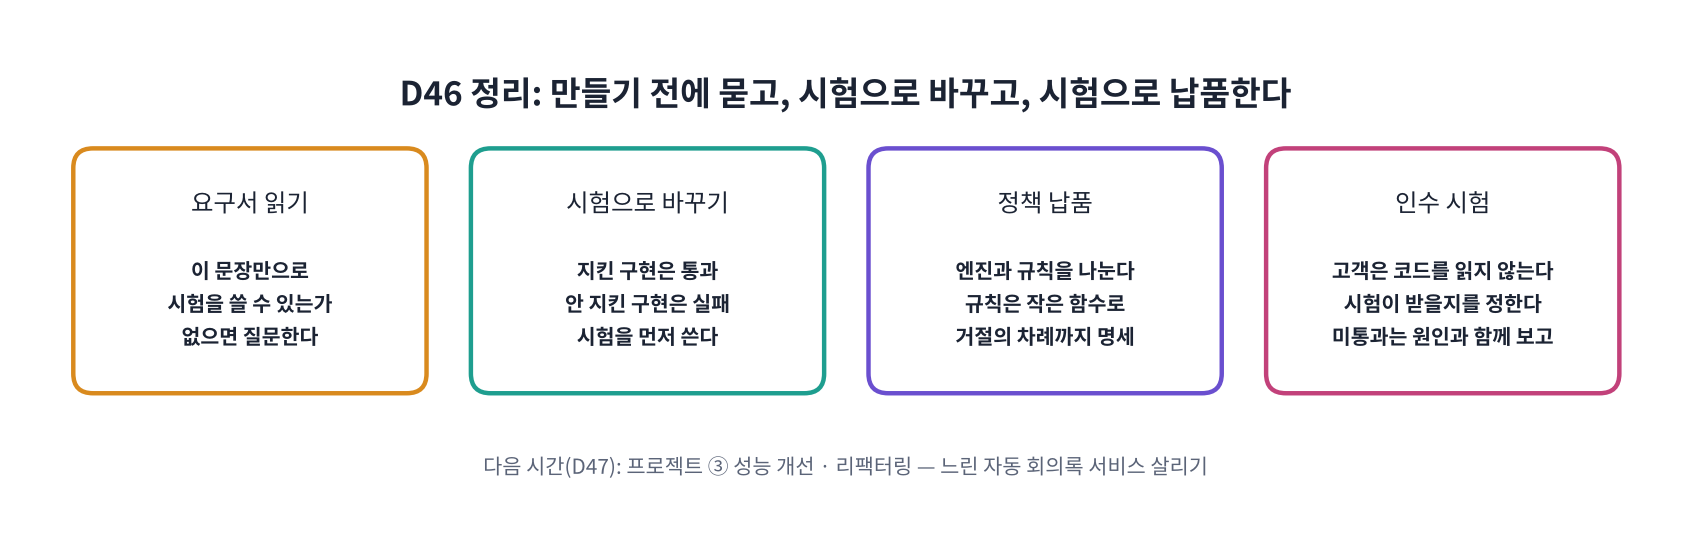

| 오늘 한 일 | 배운 것 |
|---|---|
| 요구서 읽기 · 질문 | "이 문장만으로 시험을 쓸 수 있는가?" 쓸 수 없으면 만들기 전에 묻는다 |
| 내 인수 시험 쓰기 | 좋은 시험은 지킨 구현은 통과시키고 안 지킨 구현은 떨어뜨린다 |
| 정책 8개 | 자주 바뀌는 규칙과 잘 안 바뀌는 흐름을 나눈다. 예시를 통과했다고 요구사항을 지킨 것은 아니다 |
| 납품 | 고객은 코드를 읽지 않는다. 시험이 받을지를 정한다 |
| 보고서 | 통과율과 함께 원인 · 확인하지 못한 것 · 되물을 것을 적는다 |

**오늘의 산출물**: `delivery_report.html` · `delivery.json` · 내 인수 시험(`MY_TESTS`) · 정책 8개

### ✍️ 회고 (5분 · 아래에 직접 적어 보세요)

1. 1교시에 **묻지 않아서** 4교시에 떨어진 시험이 있었나요? 어떤 질문을 했어야 했나요?
2. 요구서의 예시는 통과했는데 인수 시험에서 떨어진 정책이 있었나요? 무엇이 달랐나요?
3. 내가 쓴 시험 가운데 실제로 내 실수를 잡아 준 것이 있었나요?

> ⚠️ **오늘 하지 않은 것**: 실제 전화선(SIP)과 전화 음질에서의 시험, LiveKit의 `session.run`으로 돌리는 진짜 LLM 에이전트(오늘은 같은 모양의 규칙 엔진), 실제 사람의 목소리, 한글로 읽은 전화번호 받기, 동시에 걸려 오는 전화, 예약 시스템과의 실제 연동. 오늘의 통화 엔진은 수업용이며 병원 · 환자 · 예약은 모두 가상입니다.

**내일(D47)은 또 형식이 바뀝니다.** 새로 만들지 않습니다. 일부러 느리고 비싸게 짠 **자동 회의록 서비스의 코드**를 받아, 무엇이 느린지 재고, 목표치(처리 시간 · 비용 · 정확도)에 맞게 고칩니다. 오늘은 "요구서대로 만들었는가"였고, 내일은 "**돌아가는 것을 더 낫게** 만들었는가"입니다.